In [1]:
!pip install astropy

In [2]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt

print("SPHEREx analysis environment is ready!")

SPHEREx analysis environment is ready!


In [3]:

# Download SPHEREx FITS data from NASA

url = "https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/12b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits"

!wget -O spherex.fits "$url"


--2026-11-13 15:35:54--  https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/12b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits
Resolving irsa.ipac.caltech.edu (irsa.ipac.caltech.edu)... 134.4.54.42
Connecting to irsa.ipac.caltech.edu (irsa.ipac.caltech.edu)|134.4.54.42|:443... connected.
HTTP request sent, awaiting response... 404 Not Found
2026-11-13 15:35:55 ERROR 404: Not Found.



In [4]:

url = "https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/l2b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits"

!wget -O spherex.fits "$url"


--2026-11-13 15:41:43--  https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W19_1B/l2b-v27-2026-197/3/level2_2025W19_1B_0116_1D3_spx_l2b-v27-2026-197.fits
Resolving irsa.ipac.caltech.edu (irsa.ipac.caltech.edu)... 134.4.54.42
Connecting to irsa.ipac.caltech.edu (irsa.ipac.caltech.edu)|134.4.54.42|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 65790720 (63M) [application/fits]
Saving to: ‘spherex.fits’

spherex.fits        100%[===================>]  62.74M  7.73MB/s    in 16s     

2026-11-13 15:42:00 (3.86 MB/s) - ‘spherex.fits’ saved [65790720/65790720]



In [5]:

# Open the SPHEREx FITS file

hdul = fits.open("spherex.fits")

# Display the FITS structure
hdul.info()


Filename: spherex.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       276   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     55   451R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 14J, 252E]   


In [6]:

# Inspect important FITS extensions

for name in ["IMAGE", "FLAGS", "VARIANCE"]:

    print("\n" + "=" * 40)
    print("HDU:", name)
    print("=" * 40)

    header = hdul[name].header

    print("Dimensions:", hdul[name].data.shape)
    print("Data Type:", hdul[name].data.dtype)

    print("\nHeader Information:")
    print(header)



HDU: IMAGE
Dimensions: (2040, 2040)
Data Type: >f4

Header Information:
XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                  -32 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                 2040                                                  NAXIS2  =                 2040                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               EXTNAME = 'IMAGE   '           / extension name                                 EXTTYPE = 'IMAGE   '           / Extension supports mask overlay                BUNIT   = 'MJy / sr'           / Unit of pixel value                            DETECTOR=                    3 / 1-3: SWIR, 4-6: MWIR                           OBSID   = '2025W19_1B_0116_1'  / Observation ID

In [ ]:

# Extract the three data arrays

image = hdul["IMAGE"].data
flags = hdul["FLAGS"].data
variance = hdul["VARIANCE"].data

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# IMAGE
im1 = axes[0].imshow(
    image,
    origin="lower",
    cmap="gray",
    vmin=np.nanpercentile(image, 1),
    vmax=np.nanpercentile(image, 99)
)
axes[0].set_title("IMAGE")
plt.colorbar(im1, ax=axes[0])

# FLAGS
im2 = axes[1].imshow(flags, origin="lower", cmap="viridis")
axes[1].set_title("FLAGS")
plt.colorbar(im2, ax=axes[1])

# VARIANCE
im3 = axes[2].imshow(
    variance,
    origin="lower",
    cmap="magma",
    vmin=np.nanpercentile(variance, 1),
    vmax=np.nanpercentile(variance, 99)
)
axes[2].set_title("VARIANCE")
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()


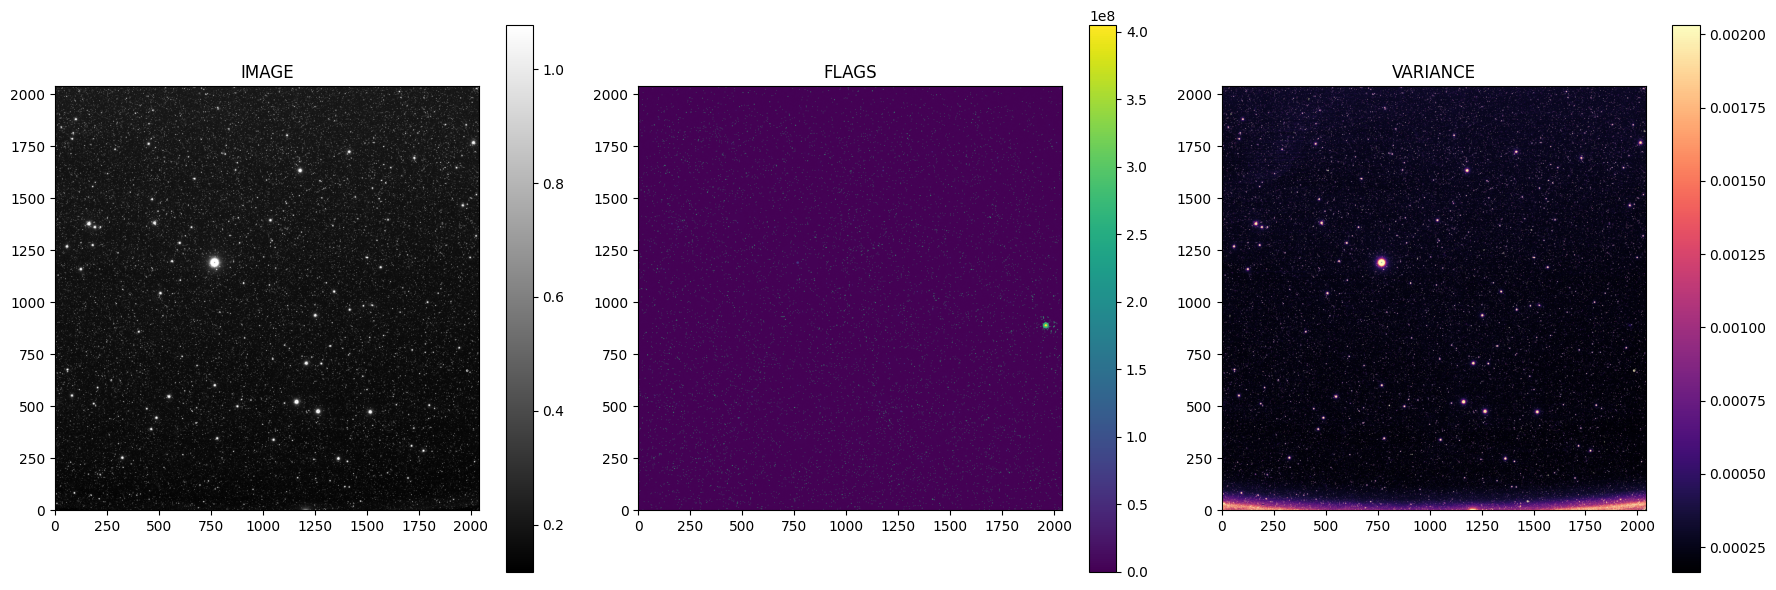

In [7]:

# Extract the three data arrays

image = hdul["IMAGE"].data
flags = hdul["FLAGS"].data
variance = hdul["VARIANCE"].data

# Create three plots
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# IMAGE
im1 = axes[0].imshow(
    image,
    origin="lower",
    cmap="gray",
    vmin=np.nanpercentile(image, 1),
    vmax=np.nanpercentile(image, 99)
)
axes[0].set_title("IMAGE")
plt.colorbar(im1, ax=axes[0])

# FLAGS
im2 = axes[1].imshow(flags, origin="lower", cmap="viridis")
axes[1].set_title("FLAGS")
plt.colorbar(im2, ax=axes[1])

# VARIANCE
im3 = axes[2].imshow(
    variance,
    origin="lower",
    cmap="magma",
    vmin=np.nanpercentile(variance, 1),
    vmax=np.nanpercentile(variance, 99)
)
axes[2].set_title("VARIANCE")
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()
plt.show()


In [9]:

# Numerical analysis of SPHEREx data

print("========== IMAGE ==========")
print("Minimum:", np.nanmin(image))
print("Maximum:", np.nanmax(image))
print("Mean:", np.nanmean(image))
print("NaN pixels:", np.isnan(image).sum())

print("\n========== FLAGS ==========")
unique_flags, counts = np.unique(flags, return_counts=True)

print("Number of unique values:", len(unique_flags))

print("\nFlag values and their counts:")
for value, count in zip(unique_flags, counts):
    print(f"Value: {value}, Count: {count}")

print("\n========== VARIANCE ==========")
print("Minimum:", np.nanmin(variance))
print("Maximum:", np.nanmax(variance))
print("Mean:", np.nanmean(variance))
print("NaN pixels:", np.isnan(variance).sum())


========== IMAGE ==========
Minimum: -9997.668
Maximum: 48396.996
Mean: 0.34205776
NaN pixels: 233

========== FLAGS ==========
Number of unique values: 87

Flag values and their counts:
Value: 0, Count: 1873676
Value: 64, Count: 2221
Value: 65, Count: 268
Value: 66, Count: 11
Value: 69, Count: 2381
Value: 70, Count: 94
Value: 71, Count: 3
Value: 128, Count: 52191
Value: 192, Count: 199
Value: 193, Count: 11
Value: 197, Count: 58
Value: 198, Count: 3
Value: 2112, Count: 1
Value: 2117, Count: 597
Value: 2245, Count: 21
Value: 4224, Count: 159
Value: 4288, Count: 2
Value: 4293, Count: 1
Value: 131072, Count: 792
Value: 131200, Count: 17
Value: 524288, Count: 75412
Value: 655360, Count: 49
Value: 2097152, Count: 2038682
Value: 2097154, Count: 285
Value: 2097216, Count: 2383
Value: 2097217, Count: 298
Value: 2097218, Count: 9
Value: 2097221, Count: 2576
Value: 2097222, Count: 86
Value: 2097223, Count: 2
Value: 2097280, Count: 55392
Value: 2097282, Count: 4
Value: 2097344, Count: 178
Value:

In [10]:

# Decode SPHEREx FLAGS bitmask

flag_definitions = {
    0: "TRANSIENT",
    1: "OVERFLOW",
    2: "SUR_ERROR",
    6: "NONFUNC",
    7: "DICHROIC"
}

print("SPHEREx FLAGS Analysis")
print("-" * 45)

for bit, name in flag_definitions.items():

    mask = (flags & (1 << bit)) != 0

    print(
        f"{name}: {np.count_nonzero(mask)} pixels"
    )

print("-" * 45)

print("Pixels with no flags:",
      np.count_nonzero(flags == 0))

print("Total pixels:", flags.size)


SPHEREx FLAGS Analysis
---------------------------------------------
TRANSIENT: 19713 pixels
OVERFLOW: 829 pixels
SUR_ERROR: 13527 pixels
NONFUNC: 12153 pixels
DICHROIC: 109713 pixels
---------------------------------------------
Pixels with no flags: 1873676
Total pixels: 4161600


In [11]:
print("VARIANCE ANALYSIS")

print("Minimum:", np.nanmin(variance))
print("Maximum:", np.nanmax(variance))
print("Mean:", np.nanmean(variance))
print("Median:", np.nanmedian(variance))
print("NaN pixels:", np.isnan(variance).sum())

VARIANCE ANALYSIS
Minimum: 1.5366577e-06
Maximum: 2.1015505e+06
Mean: 0.71973157
Median: 0.00023914097
NaN pixels: 233


In [12]:

# Read official flag definitions from FITS header

flags_header = hdul["FLAGS"].header

print("SPHEREx FLAGS definitions")
print("=" * 50)

for key, value in flags_header.items():
    if key.startswith("MP_"):
        print(f"{key}: {value}")

print("\nAdditional quality information:")
for key, value in flags_header.items():
    if "L2 N_" in key:
        print(f"{key}: {value}")


SPHEREx FLAGS definitions

Additional quality information:


In [13]:

# Detailed VARIANCE distribution

valid_variance = variance[np.isfinite(variance)]

print("VARIANCE Percentiles")

for p in [0, 25, 50, 75, 90, 95, 99, 99.9, 100]:
    print(f"{p}%:", np.percentile(valid_variance, p))

print("\nInvalid pixels:", np.sum(~np.isfinite(variance)))
print("Zero variance pixels:", np.sum(variance == 0))
print("Negative variance pixels:", np.sum(variance < 0))


VARIANCE Percentiles
0%: 1.5366577e-06
25%: 0.00021111101
50%: 0.00023914097
75%: 0.00027788198
90%: 0.00034761085
95%: 0.00053986197
99%: 0.002031076
99.9%: 0.05623471
100%: 2.1015505e+06

Invalid pixels: 233
Zero variance pixels: 0
Negative variance pixels: 0


In [14]:

# Search all FITS headers for flag definitions

keywords = ["MP_", "FLAG", "MASK", "QUAL", "BIT"]

for i, hdu in enumerate(hdul):

    print("\n" + "=" * 55)
    print("HDU:", i, "| Name:", hdu.name)
    print("=" * 55)

    for card in hdu.header.cards:

        key = card.keyword.upper()

        if any(word in key for word in keywords):
            print(key, ":", card.value)



HDU: 0 | Name: PRIMARY
BITPIX : 8

HDU: 1 | Name: IMAGE
BITPIX : -32
SPS_FLAGS : all_sky

HDU: 2 | Name: FLAGS
BITPIX : 32

HDU: 3 | Name: VARIANCE
BITPIX : -32

HDU: 4 | Name: ZODI
BITPIX : -32

HDU: 5 | Name: EPSF
BITPIX : 8

HDU: 6 | Name: WCS-WAVE
BITPIX : 8


In [15]:

# Display all FLAGS header information

print(hdul["FLAGS"].header)


XTENSION= 'IMAGE   '           / Image extension                                BITPIX  =                   32 / array data type                                NAXIS   =                    2 / number of array dimensions                     NAXIS1  =                 2040                                                  NAXIS2  =                 2040                                                  PCOUNT  =                    0 / number of parameters                           GCOUNT  =                    1 / number of groups                               EXTNAME = 'FLAGS   '           / name of this binary table extension            BUNIT   = '' / Unit of flag pixel value (dimensionless)                         EXTTYPE = 'MASK    '           / Extension can be used as a mask overlay        WCSAXES =                    2 / Number of coordinate axes                      CRPIX1  =               1020.5 / Pixel coordinate of reference point            CRPIX2  =               1020.5 / Pixel c

In [16]:

# Inspect the FLAGS data structure

print("FLAGS shape:", flags.shape)
print("FLAGS dtype:", flags.dtype)
print("FLAGS compression type:", type(hdul["FLAGS"]).__name__)

print("\nFirst 20 unique flag values:")
print(np.unique(flags)[:20])


FLAGS shape: (2040, 2040)
FLAGS dtype: int32
FLAGS compression type: CompImageHDU

First 20 unique flag values:
[     0     64     65     66     69     70     71    128    192    193
    197    198   2112   2117   2245   4224   4288   4293 131072 131200]


In [17]:

# Documented SPHEREx image flag definitions

flag_definitions = {
    0: "TRANSIENT",
    1: "OVERFLOW",
    2: "SUR_ERROR",
    6: "NONFUNC",
    7: "DICHROIC",
    9: "MISSING_DATA",
    10: "HOT",
    11: "COLD",
    12: "FULLSAMPLE",
    14: "PHANMISS",
    15: "NONLINEAR",
    17: "PERSIST",
    19: "OUTLIER",
    20: "CROSSTALK",
    21: "SOURCE",
    22: "GHOST"
}

print("Complete documented FLAGS analysis")
print("=" * 55)

for bit, name in flag_definitions.items():

    mask = (flags & (1 << bit)) != 0
    count = np.count_nonzero(mask)

    print(f"{name:15s} | {count:10d} pixels")

print("=" * 55)
print("Total pixels:", flags.size)
print("Pixels without flags:", np.count_nonzero(flags == 0))


Complete documented FLAGS analysis
TRANSIENT       |      19713 pixels
OVERFLOW        |        829 pixels
SUR_ERROR       |      13527 pixels
NONFUNC         |      12153 pixels
DICHROIC        |     109713 pixels
MISSING_DATA    |          0 pixels
HOT             |          1 pixels
COLD            |       1766 pixels
FULLSAMPLE      |        272 pixels
PHANMISS        |          0 pixels
NONLINEAR       |          0 pixels
PERSIST         |       1905 pixels
OUTLIER         |      77002 pixels
CROSSTALK       |          0 pixels
SOURCE          |    2129157 pixels
GHOST           |          0 pixels
Total pixels: 4161600
Pixels without flags: 1873676


In [18]:
for card in hdul["FLAGS"].header.cards:
    print(card)

XTENSION= 'IMAGE   '           / Image extension                                
BITPIX  =                   32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 2040                                                  
NAXIS2  =                 2040                                                  
PCOUNT  =                    0 / number of parameters                           
GCOUNT  =                    1 / number of groups                               
EXTNAME = 'FLAGS   '           / name of this binary table extension            
BUNIT   = '' / Unit of flag pixel value (dimensionless)                         
EXTTYPE = 'MASK    '           / Extension can be used as a mask overlay        
WCSAXES =                    2 / Number of coordinate axes                      
CRPIX1  =               1020.5 / Pixel coordinate of reference point            
CRPIX2  =               1020

In [21]:

# Extract SPHEREx flag definitions from FITS header

flags_header = hdul["FLAGS"].header

definitions = flags_header["MP*"]

for key, value in definitions.items():
    print(f"{key}: {value}")


In [22]:

# Display all keywords in FLAGS header

for card in hdul["FLAGS"].header.cards:
    print(f"Keyword: {card.keyword:15s} | Comment: {card.comment}")


Keyword: XTENSION        | Comment: Image extension
Keyword: BITPIX          | Comment: array data type
Keyword: NAXIS           | Comment: number of array dimensions
Keyword: NAXIS1          | Comment: 
Keyword: NAXIS2          | Comment: 
Keyword: PCOUNT          | Comment: number of parameters
Keyword: GCOUNT          | Comment: number of groups
Keyword: EXTNAME         | Comment: name of this binary table extension
Keyword: BUNIT           | Comment: Unit of flag pixel value (dimensionless)
Keyword: EXTTYPE         | Comment: Extension can be used as a mask overlay
Keyword: WCSAXES         | Comment: Number of coordinate axes
Keyword: CRPIX1          | Comment: Pixel coordinate of reference point
Keyword: CRPIX2          | Comment: Pixel coordinate of reference point
Keyword: PC1_1           | Comment: Coordinate transformation matrix element
Keyword: PC1_2           | Comment: Coordinate transformation matrix element
Keyword: PC2_1           | Comment: Coordinate transformation ma

In [23]:

# Search all HDUs for flag-related metadata

for i, hdu in enumerate(hdul):
    print(f"\n--- HDU {i}: {hdu.name} ---")

    for card in hdu.header.cards:
        key = card.keyword.upper()

        if any(word in key for word in ["FLAG", "MASK", "QUALITY", "MP_"]):
            print(card.keyword, ":", card.value)



--- HDU 0: PRIMARY ---

--- HDU 1: IMAGE ---
SPS_FLAGS : all_sky

--- HDU 2: FLAGS ---

--- HDU 3: VARIANCE ---

--- HDU 4: ZODI ---

--- HDU 5: EPSF ---

--- HDU 6: WCS-WAVE ---


In [25]:

# Check IMAGE header for flag definitions

image_header = hdul["IMAGE"].header

print("IMAGE HEADER FLAG DEFINITIONS")
print("=" * 50)

for card in image_header.cards:
    if "MP_" in card.keyword.upper():
        print(card.keyword, ":", card.value, "|", card.comment)


IMAGE HEADER FLAG DEFINITIONS


In [26]:

# SPHEREx FITS Analysis Summary

print("========== SPHEREx FITS REPORT ==========")

print("\n1. FITS STRUCTURE")
hdul.info()

print("\n2. IMAGE")
print("Shape:", image.shape)
print("Data Type:", image.dtype)
print("Minimum:", np.nanmin(image))
print("Maximum:", np.nanmax(image))
print("Mean:", np.nanmean(image))
print("NaN pixels:", np.isnan(image).sum())

print("\n3. FLAGS")
print("Shape:", flags.shape)
print("Data Type:", flags.dtype)
print("Unique values:", len(np.unique(flags)))
print("Pixels without flags:", np.sum(flags == 0))

print("\n4. VARIANCE")
print("Shape:", variance.shape)
print("Data Type:", variance.dtype)
print("Minimum:", np.nanmin(variance))
print("Maximum:", np.nanmax(variance))
print("Median:", np.nanmedian(variance))
print("NaN pixels:", np.isnan(variance).sum())

print("\n========== ANALYSIS COMPLETED ==========")


========== SPHEREx FITS REPORT ==========

1. FITS STRUCTURE
Filename: spherex.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       276   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     55   451R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 14J, 252E]   

2. IMAGE
Shape: (2040, 2040)
Data Type: >f4
Minimum: -9997.668
Maximum: 48396.996
Mean: 0.34205776
NaN pixels: 233

3. FLAGS
Shape: (2040, 2040)
Data Type: int32
Unique values: 87
Pixels without flags: 1873676

4. VARIANCE
Shape: (2040, 2040)
Data Type: >f4
Minimum: 1.5366577e-06
Maximum: 2.1015505e+06
Median: 0.00023914097
NaN pixels: 233

========== ANALYSIS C

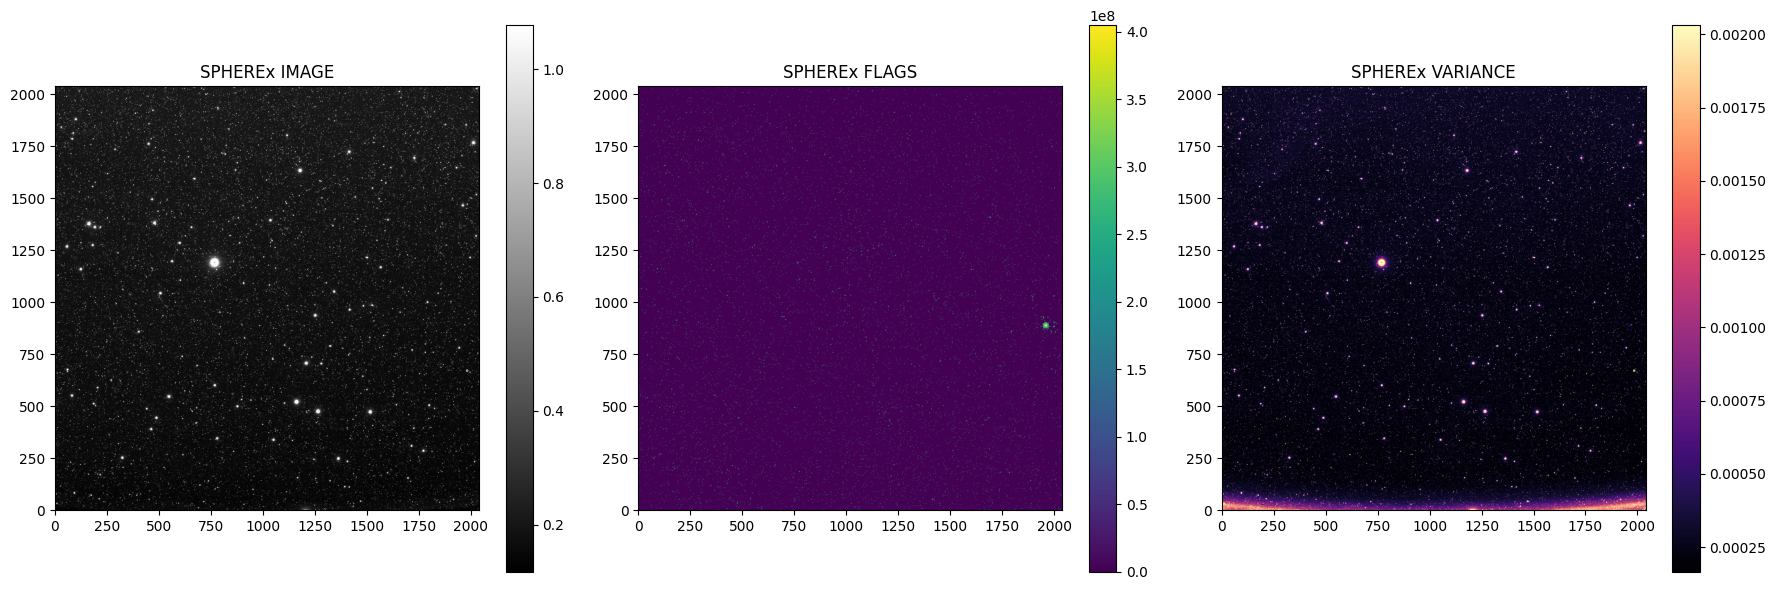

Visualization saved successfully!


In [27]:

# Save SPHEREx analysis visualizations

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

im1 = axes[0].imshow(
    image, origin="lower", cmap="gray",
    vmin=np.nanpercentile(image, 1),
    vmax=np.nanpercentile(image, 99)
)
axes[0].set_title("SPHEREx IMAGE")
plt.colorbar(im1, ax=axes[0])

im2 = axes[1].imshow(flags, origin="lower", cmap="viridis")
axes[1].set_title("SPHEREx FLAGS")
plt.colorbar(im2, ax=axes[1])

im3 = axes[2].imshow(
    variance, origin="lower", cmap="magma",
    vmin=np.nanpercentile(variance, 1),
    vmax=np.nanpercentile(variance, 99)
)
axes[2].set_title("SPHEREx VARIANCE")
plt.colorbar(im3, ax=axes[2])

plt.tight_layout()

plt.savefig(
    "SPHEREx_FITS_Analysis.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved successfully!")
